In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import os



# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)

    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(Q, nbins=30, unfolded_cutoff=0.1, wopt=None):
    k = 0.008314
    T = 293.0
    kT = k * T

    
    if wopt is None:
        wopt = np.ones(Q.shape[0])/Q.shape[0]
        

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q)
    centers_post, fel_post = compute_FEL(Q, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q > native_cutoff)[0]

    dG_prior = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q > native_cutoff2)[0]
    unfolded = np.where(Q < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]


proteins = ['EEHEE_rd4_0871-No-His']
ensemble_master_dir = 'BIOEMU_DATA'

In [2]:
# gather all the data

path = '../BIOEMU_DATA/'

ntrajs = 10

phi_threshold = 0.1

data = {}

for protein in proteins:
    data[protein] = {}

    phis = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/phis.txt")
    chi2r = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/chi2r.txt")
    rmse = np.loadtxt(path+protein+"/HDXrew_M14DH_scaled/rmse.txt")
    wopt_array = np.load(path+protein+"/HDXrew_M14DH_scaled/wopt_array.npy")
    pred_array = np.load(path+protein+"/HDXrew_M14DH_scaled/pred_uptakes.npy")

    stop_idx= np.where(phis<phi_threshold)[0][0]
    print(stop_idx)
    phis = phis[:stop_idx]
    chi2r = chi2r[:stop_idx]
    rmse = rmse[:stop_idx]
    wopt_array = wopt_array[:stop_idx]
    pred_array = pred_array[:stop_idx]

    data[protein]['phi'] = phis
    data[protein]['chi2r'] = chi2r
    data[protein]['rmse'] = rmse
    data[protein]['wopt_array'] = wopt_array
    data[protein]['pred_array'] = pred_array

        
phi = data[protein]['phi']
rmse = data[protein]['rmse']
pred_array = np.array(data[protein]['pred_array'])

elidx, elx, ely = find_elbow(phi, rmse)
elidx = elidx + 1
print(elidx)

print('done')


27
14
done


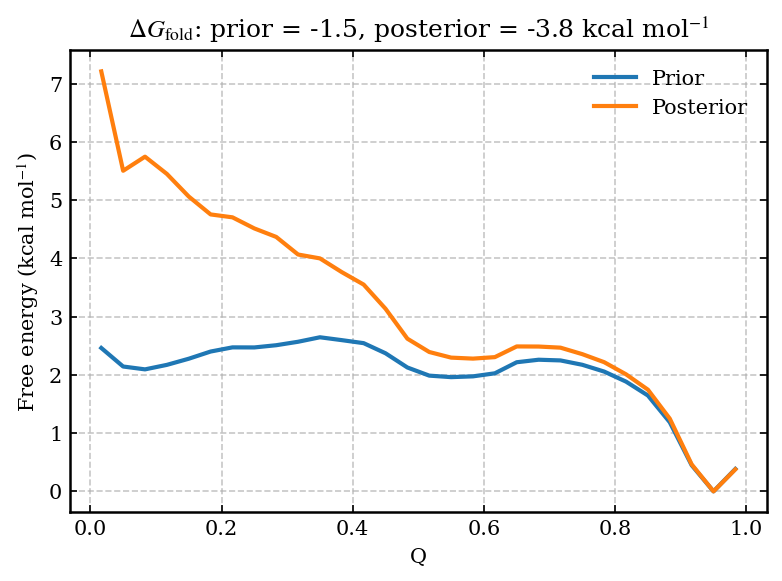

In [4]:
# free energy landscape of folding as a function of Q

ntrajs = 10
nbins = 30

k = 0.008314
T = 293.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
unfolded_cutoff = 0.35

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    if traj == trajs[0]:
        Q = np.loadtxt(f'../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
        okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        Q = Q[okframes]
    else:
        tmpQ = np.loadtxt(f'../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
        okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        Q = np.concatenate((Q, tmpQ[okframes]), axis=0)

w_prior = np.ones(len(Q))/len(Q)
w_post = data[protein]['wopt_array'][elidx]

# calculate folding free energies
folded = np.where(Q > unfolded_cutoff)[0]
unfolded = np.where(Q < unfolded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use the same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(Q, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('Q')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

-3.18
0.04
-1.5157324212038994
-3.8135365918364883
-3.7620858645555972


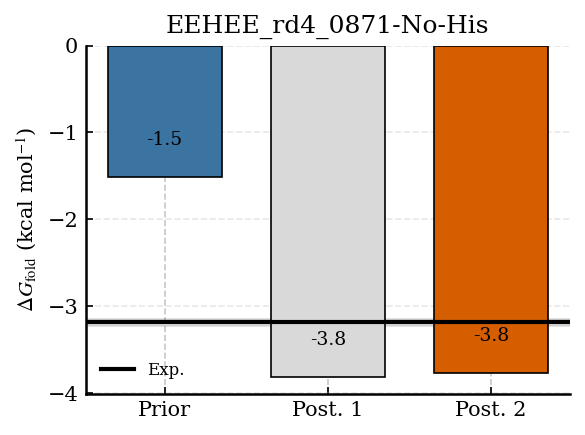

In [29]:
# barplot comparing experimental, prior, posterior 1, and posterior 2 folding free energies

protein = proteins[0]

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

# experimental dG
exp_dG, exp_dG_err = np.loadtxt(f'../ORTHOGONAL_EXP_DATA/{protein}/dG.dat', unpack=True)

# prior + posterior 1 (elbow)
_, _, _, _, _, _, dG_prior, dG_post1, _, native_cutoff = compute_free_energy(Q=Q, wopt=data[protein]['wopt_array'][elidx])

# prior + posterior 2 (final)
_, _, _, _, _, _, _, dG_post2, _, native_cutoff = compute_free_energy(Q=Q, wopt=data[protein]['wopt_array'][-1])

print(exp_dG)
print(exp_dG_err)
print(dG_prior)
print(dG_post1)
print(dG_post2)

labels = ['Prior', 'Post. 1', 'Post. 2']
values = [dG_prior, dG_post1, dG_post2]
colors = [COLOR3, COLOR2, COLOR1]
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(4, 3))

bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.8, width=0.7, zorder=3)

# experimental value as black horizontal line
ax.axhline(exp_dG, color='black', lw=2, zorder=5, label='Exp.')

# optional experimental uncertainty band
ax.axhspan(exp_dG - exp_dG_err, exp_dG + exp_dG_err, color='black', alpha=0.10, zorder=1)

# value labels
for xi, yi in zip(x, values):
    ax.text(xi, yi + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0] if ax.get_ylim()[1] > ax.get_ylim()[0] else 1), f'{yi:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(r'$\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
ax.set_title(protein)
ax.legend(frameon=False, fontsize=8, loc='best')

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig(f'{protein}_dG_barplot.pdf', dpi=300)
plt.show()

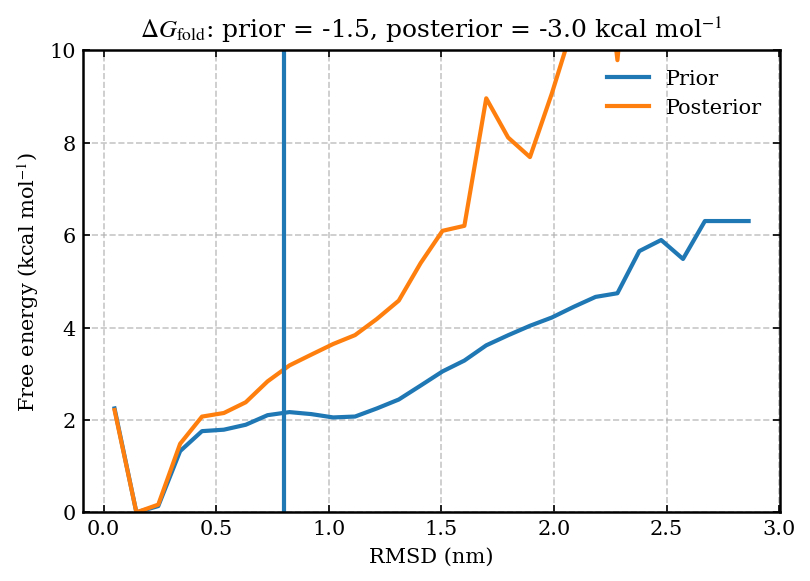

In [30]:
# free energy landscape of folding as a function of rmsd

ntrajs = 10
nbins = 30

k = 0.008314
T = 298.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
folded_cutoff = 0.8

# load rmsd and frames data
for traj in trajs:
    if traj == trajs[0]:
        rmsd = np.loadtxt(f'../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        rmsd = rmsd[okframes]
    else:
        tmprmsd = np.loadtxt(f'../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        rmsd = np.concatenate((rmsd, tmprmsd[okframes]), axis=0)

w_prior = np.ones(len(rmsd))/len(rmsd)
w_post = data[protein]['wopt_array'][elidx]

# calculate folding free energies
folded = np.where(rmsd < folded_cutoff)[0]
unfolded = np.where(rmsd > folded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(rmsd, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(rmsd, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(rmsd, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')
plt.ylim(0,10)
plt.axvline(0.8)

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('RMSD (nm)')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

In [31]:
print(Q.shape)
print(rmsd.shape)

(95761,)
(95761,)


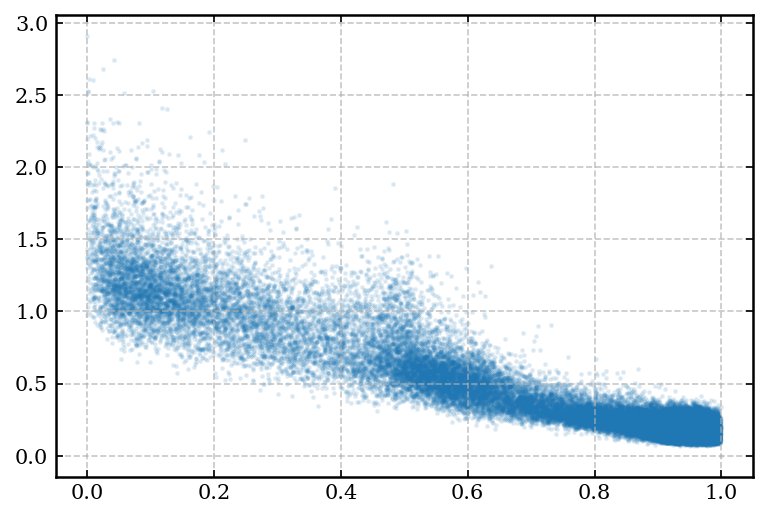

In [32]:
plt.scatter(Q, rmsd , alpha=0.1, s=2)

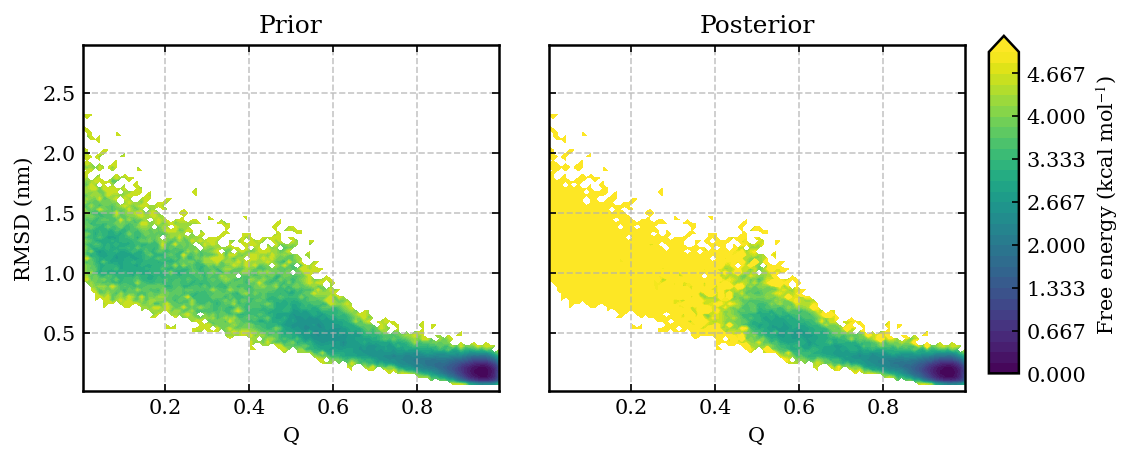

In [33]:
# 2D histogram: Q vs RMSD, prior and posterior

bins = 100
max_energy = 5  # kcal mol^-1

w_prior = np.ones(len(Q)) / len(Q)
w_post = data[protein]['wopt_array'][elidx]

q_edges = np.linspace(np.min(Q), np.max(Q), bins + 1)
rmsd_edges = np.linspace(np.min(rmsd), np.max(rmsd), bins + 1)

H_prior, _, _ = np.histogram2d(Q, rmsd, bins=[q_edges, rmsd_edges], weights=w_prior, density=True)
H_post, _, _ = np.histogram2d(Q, rmsd, bins=[q_edges, rmsd_edges], weights=w_post, density=True)

H_prior[H_prior == 0] = np.nan
H_post[H_post == 0] = np.nan

kB = 0.008314462618  # kJ mol^-1 K^-1
T = 298.0
conv = 0.239005736   # kJ -> kcal

F_prior = -kB * T * np.log(H_prior) * conv
F_post = -kB * T * np.log(H_post) * conv

F_prior -= np.nanmin(F_prior)
F_post -= np.nanmin(F_post)

q_centers = 0.5 * (q_edges[:-1] + q_edges[1:])
rmsd_centers = 0.5 * (rmsd_edges[:-1] + rmsd_edges[1:])

levels = np.linspace(0, max_energy, 31)

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.12, right=0.86)

cf1 = axes[0].contourf(q_centers, rmsd_centers, F_prior.T, levels=levels, extend='max')
cf2 = axes[1].contourf(q_centers, rmsd_centers, F_post.T, levels=levels, extend='max')

axes[0].set_title('Prior')
axes[1].set_title('Posterior')
axes[0].set_xlabel('Q')
axes[1].set_xlabel('Q')
axes[0].set_ylabel('RMSD (nm)')

cax = fig.add_axes([0.88, 0.15, 0.025, 0.75])
cbar = fig.colorbar(cf2, cax=cax)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')

plt.show()

/tmp/ipykernel_316883/3324052304.py:81: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


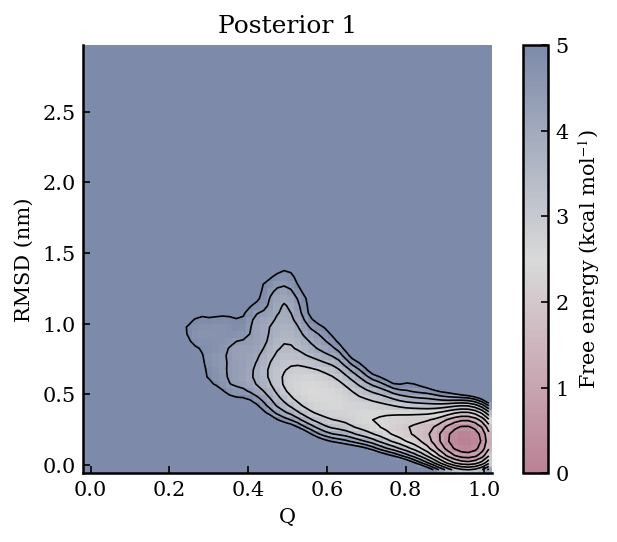

In [34]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 5.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# posterior 1 weights
wopt = np.asarray(data[protein]['wopt_array'][elidx], dtype=float)

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 293.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(f'{protein}_Q_RMSD_FEL_post1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_316883/250493595.py:81: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


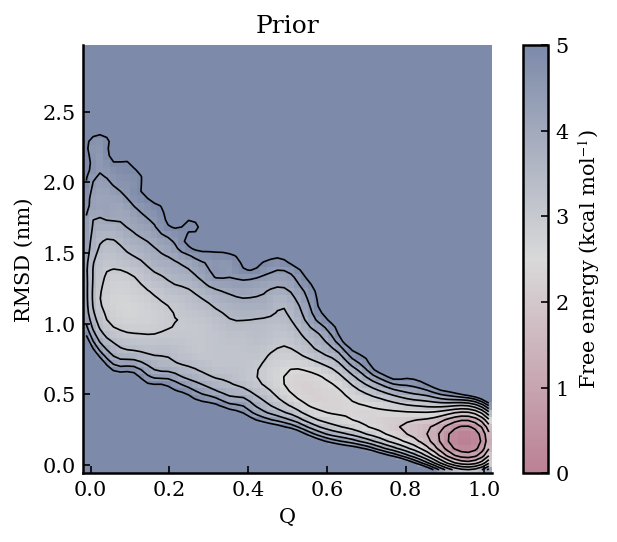

In [35]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 5.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# prior weights
wopt = np.asarray(data[protein]['wopt_array'][0], dtype=float)

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize prior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 293.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(f'{protein}_Q_RMSD_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

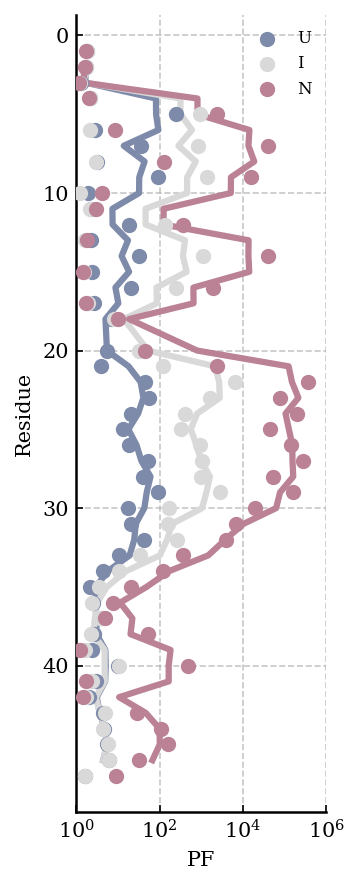

In [36]:
# protection profiles of U, I and N substates after reweighting
# Q already loaded
# U: Q < 0.35
# I: 0.35 < Q < 0.7
# N: Q > 0.7

res = np.loadtxt('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/O.npy')
synframes = 0
wopt = data['EEHEE_rd4_0871-No-His']['wopt_array'][elidx]

COLOR3 = "#7D8AA9"  # blue
COLOR2 = "#D9D9D9"  # grey
COLOR1 = "#BB8194"  # orange

# if synthetic frames are appended in the weights, remove them there
w_use = wopt[:len(wopt)-synframes] if synframes > 0 else wopt

# make sure everything has matching frame count
n_frames = min(len(Q), fopen.shape[0], len(w_use))
Q_use = Q[:n_frames]
fopen_use = fopen[:n_frames]
w_use = w_use[:n_frames]

# define substates
mask_U = Q_use < 0.35
mask_I = (Q_use > 0.35) & (Q_use < 0.7)
mask_N = Q_use > 0.7

# posterior-weighted protection factors within each substate
PF_U = 1.0 / np.average(fopen_use[mask_U], axis=0, weights=w_use[mask_U])
PF_I = 1.0 / np.average(fopen_use[mask_I], axis=0, weights=w_use[mask_I])
PF_N = 1.0 / np.average(fopen_use[mask_N], axis=0, weights=w_use[mask_N])

PF_U_plot = PF_U
PF_I_plot = PF_I
PF_N_plot = PF_N


# moving-average smoothing
window_size = 3
kernel = np.ones(window_size) / window_size
PF_U_smooth = np.convolve(PF_U_plot, kernel, mode='valid')
PF_I_smooth = np.convolve(PF_I_plot, kernel, mode='valid')
PF_N_smooth = np.convolve(PF_N_plot, kernel, mode='valid')
res_smooth = res[window_size//2:len(res)-window_size//2]

# plot
plt.figure(figsize=(2.5, 6))

plt.scatter(PF_U_plot, res, color=COLOR3, label='U', zorder=20, s=40)
plt.scatter(PF_I_plot, res, color=COLOR2, label='I', zorder=20, s=40)
plt.scatter(PF_N_plot, res, color=COLOR1, label='N', zorder=20, s=40)

plt.plot(PF_U_smooth, res_smooth, color=COLOR3, lw=3)
plt.plot(PF_I_smooth, res_smooth, color=COLOR2, lw=3)
plt.plot(PF_N_smooth, res_smooth, color=COLOR1, lw=3)

plt.xlabel('PF')
plt.ylabel('Residue')
plt.xscale('log')
plt.xlim(1, 1e6)
plt.gca().invert_yaxis()
plt.legend(loc='best', fontsize=8, frameon=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().tick_params(top=False, right=False)

plt.tight_layout()
plt.savefig('substate_residue_PFs_reweighted_post1.pdf', dpi=300)
plt.show()

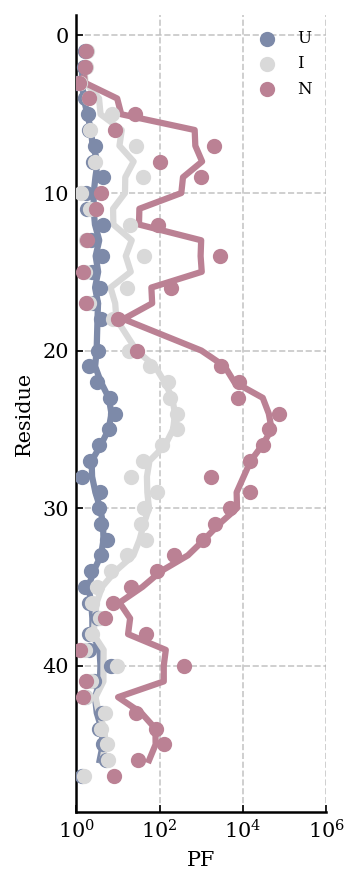

In [37]:
# protection profiles of U, I and N substates before reweighting
# Q already loaded
# U: Q < 0.35
# I: 0.35 < Q < 0.7
# N: Q > 0.7

res = np.loadtxt('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/amideresidues.txt').astype(int)
fopen = np.load('../BIOEMU_DATA/EEHEE_rd4_0871-No-His/M14DH_scaled/O.npy')
synframes = 0
wopt = data['EEHEE_rd4_0871-No-His']['wopt_array'][0] # prior weights

COLOR3 = "#7D8AA9"  # blue
COLOR2 = "#D9D9D9"  # grey
COLOR1 = "#BB8194"  # orange

# if synthetic frames are appended in the weights, remove them there
w_use = wopt[:len(wopt)-synframes] if synframes > 0 else wopt

# make sure everything has matching frame count
n_frames = min(len(Q), fopen.shape[0], len(w_use))
Q_use = Q[:n_frames]
fopen_use = fopen[:n_frames]
w_use = w_use[:n_frames]

# define substates
mask_U = Q_use < 0.35
mask_I = (Q_use > 0.35) & (Q_use < 0.7)
mask_N = Q_use > 0.7

# posterior-weighted protection factors within each substate
PF_U = 1.0 / np.average(fopen_use[mask_U], axis=0, weights=w_use[mask_U])
PF_I = 1.0 / np.average(fopen_use[mask_I], axis=0, weights=w_use[mask_I])
PF_N = 1.0 / np.average(fopen_use[mask_N], axis=0, weights=w_use[mask_N])

PF_U_plot = PF_U
PF_I_plot = PF_I
PF_N_plot = PF_N

# moving-average smoothing
window_size = 3
kernel = np.ones(window_size) / window_size
PF_U_smooth = np.convolve(PF_U_plot, kernel, mode='valid')
PF_I_smooth = np.convolve(PF_I_plot, kernel, mode='valid')
PF_N_smooth = np.convolve(PF_N_plot, kernel, mode='valid')
res_smooth = res[window_size//2:len(res)-window_size//2]

# plot
plt.figure(figsize=(2.5, 6))

plt.scatter(PF_U_plot, res, color=COLOR3, label='U', zorder=20, s=40)
plt.scatter(PF_I_plot, res, color=COLOR2, label='I', zorder=20, s=40)
plt.scatter(PF_N_plot, res, color=COLOR1, label='N', zorder=20, s=40)

plt.plot(PF_U_smooth, res_smooth, color=COLOR3, lw=3)
plt.plot(PF_I_smooth, res_smooth, color=COLOR2, lw=3)
plt.plot(PF_N_smooth, res_smooth, color=COLOR1, lw=3)

plt.xlabel('PF')
plt.ylabel('Residue')
plt.xscale('log')
plt.xlim(1, 1e6)
plt.gca().invert_yaxis()
plt.legend(loc='best', fontsize=8, frameon=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().tick_params(top=False, right=False)

plt.tight_layout()
plt.savefig('substate_residue_PFs_reweighted_prior.pdf', dpi=300)
plt.show()

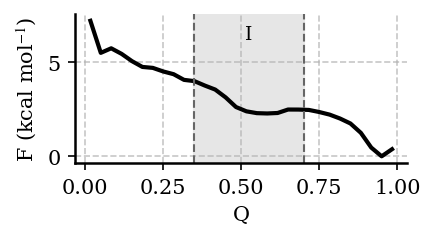

In [19]:
# plot 1D FEL
# free energy landscape of folding as a function of Q

ntrajs = 10
nbins = 30

k = 0.008314
T = 293.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# state boundaries
U_cutoff = 0.35
I_cutoff = 0.70

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    tmpQ = np.loadtxt(f'../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
    okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)

    if traj == trajs[0]:
        Q = tmpQ[okframes]
    else:
        Q = np.concatenate((Q, tmpQ[okframes]), axis=0)

w_post = data[protein]['wopt_array'][elidx]

# calculate folding free energy: folded vs unfolded
folded = np.where(Q > U_cutoff)[0]
unfolded = np.where(Q < U_cutoff)[0]

dG_post = -kT * np.log(
    np.sum(w_post[folded]) / np.sum(w_post[unfolded])
) * kj_to_kcal

# calculate posterior FEL
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)
p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

# intermediate-state region: 0.35 < Q < 0.7
ax.axvspan(U_cutoff, I_cutoff, color="0.9", zorder=0)
ax.axvline(U_cutoff, color="0.4", ls="--", lw=1)
ax.axvline(I_cutoff, color="0.4", ls="--", lw=1)

ax.text(
    (U_cutoff + I_cutoff) / 2,
    ax.get_ylim()[1] * 0.92,
    "I",
    ha="center",
    va="top",
    fontsize=9
)

ax.set_xlabel("Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")



ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig(
    f'posterior_fel_1D_Q.pdf',
    bbox_inches="tight"
)
plt.show()

In [39]:
# save top 10 highest-weight conformers closest to the intermediate-state FEL minimum

import mdtraj as md
from pathlib import Path

q_low = 0.35
q_high = 0.70
n_conformers = 10

base_dir = Path(f'../{ensemble_master_dir}/{protein}')
out_dir = Path('intermediate_FELminimum_top10')
out_dir.mkdir(exist_ok=True)

trajs = sorted(find_xtc_filenames(base_dir))

Q_all, traj_all, frame_all = [], [], []

for i, traj in enumerate(trajs):
    Q = np.loadtxt(base_dir / f'native_contacts/Q{i}.txt')
    okframes = np.loadtxt(base_dir / f'M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)

    Q_all.append(Q[okframes])
    traj_all.extend([traj] * len(okframes))
    frame_all.extend(okframes)

Q_all = np.concatenate(Q_all)
traj_all = np.array(traj_all)
frame_all = np.array(frame_all)

# posterior weights used in the FEL
w_post = data[protein]['wopt_array'][elidx]

# ------------------------------------------------------------
# Reconstruct the same 1D posterior FEL used in the plot
# ------------------------------------------------------------

nbins = 30

k = 0.008314
T = 293.0
kT = k * T
kj_to_kcal = 0.239005736

bin_edges = np.histogram_bin_edges(Q_all, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(Q_all, bins=bin_edges, weights=w_post)
p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# ------------------------------------------------------------
# Find FEL minimum within intermediate-state region
# ------------------------------------------------------------

I_bins = np.where(
    (bin_centers > q_low) &
    (bin_centers < q_high) &
    np.isfinite(fel_post)
)[0]

I_min_bin = I_bins[np.argmin(fel_post[I_bins])]
Q_I_min = bin_centers[I_min_bin]
F_I_min = fel_post[I_min_bin]

print(f'Intermediate FEL minimum:')
print(f'Q = {Q_I_min:.4f}')
print(f'Free energy = {F_I_min:.3f} kcal mol^-1')
print()

# ------------------------------------------------------------
# Find structures closest in Q to the FEL minimum
# ------------------------------------------------------------

intermediate = np.where((Q_all > q_low) & (Q_all < q_high))[0]

distance_to_min = np.abs(Q_all[intermediate] - Q_I_min)

# sort first by closeness to Q minimum, then by posterior weight
order = np.lexsort(
    (-w_post[intermediate], distance_to_min)
)

top = intermediate[order[:n_conformers]]

print(f'Intermediate-state frames: {len(intermediate)}')
print(f'Posterior population: {np.sum(w_post[intermediate]):.4f}')
print()

# ------------------------------------------------------------
# Save conformers
# ------------------------------------------------------------

for rank, idx in enumerate(top, 1):
    traj_name = traj_all[idx]
    frame = frame_all[idx]

    structure = md.load_frame(
        str(base_dir / traj_name),
        int(frame),
        top=str(base_dir / 'protein.pdb')
    )

    outfile = out_dir / (
        f'intermediate_{rank:02d}_'
        f'Q{Q_all[idx]:.4f}_'
        f'dQ{abs(Q_all[idx] - Q_I_min):.4f}_'
        f'w{w_post[idx]:.6g}.pdb'
    )

    structure.save_pdb(str(outfile))

    print(
        f'{rank:2d}: {traj_name}, frame {frame:6d}, '
        f'Q = {Q_all[idx]:.4f}, '
        f'|Q-Qmin| = {abs(Q_all[idx] - Q_I_min):.4f}, '
        f'weight = {w_post[idx]:.6g}'
    )

Intermediate FEL minimum:
Q = 0.5833
Free energy = 2.279 kcal mol^-1

Intermediate-state frames: 8706
Posterior population: 0.0522

 1: traj5.xtc, frame    294, Q = 0.5833, |Q-Qmin| = 0.0000, weight = 1.10452e-05
 2: traj6.xtc, frame   1857, Q = 0.5834, |Q-Qmin| = 0.0000, weight = 1.71123e-06
 3: traj6.xtc, frame   5331, Q = 0.5833, |Q-Qmin| = 0.0001, weight = 2.063e-07
 4: traj7.xtc, frame   8013, Q = 0.5833, |Q-Qmin| = 0.0001, weight = 1.00172e-05
 5: traj3.xtc, frame   7569, Q = 0.5833, |Q-Qmin| = 0.0001, weight = 1.05542e-05
 6: traj0.xtc, frame   7108, Q = 0.5832, |Q-Qmin| = 0.0001, weight = 9.76079e-06
 7: traj7.xtc, frame     69, Q = 0.5832, |Q-Qmin| = 0.0001, weight = 7.44131e-06
 8: traj1.xtc, frame   4593, Q = 0.5835, |Q-Qmin| = 0.0001, weight = 3.92787e-06
 9: traj5.xtc, frame   6674, Q = 0.5832, |Q-Qmin| = 0.0002, weight = 9.12206e-06
10: traj1.xtc, frame   8100, Q = 0.5832, |Q-Qmin| = 0.0002, weight = 9.72373e-06


In [21]:
# secondary structure

import mdtraj as md

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# Function to calculate per-residue helicity per frame
def dssp_to_strand(dssp_lines):
    """
    same thing for beta strand
    """
    strand_codes = {'E', 'B'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    strandicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        strandicity[i, :] = [1 if c in strand_codes else 0 for c in line]
    
    return strandicity

# comparison with secondary structure / helicity
path = '../BIOEMU_DATA/EEHEE_rd4_0871-No-His/'

traj_names = np.sort(find_xtc_filenames(path))

dssp_all = []

for traj in traj_names:
    u = md.load(
        path + f'./{traj}',
        top=path + f'./protein.pdb'
    )

    okframes = np.loadtxt(path+f'M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)

    heavyatoms = u.topology.select('not element H')
    u = u.atom_slice(heavyatoms)

    tmpdssp = md.compute_dssp(u)
    dssp_all.append(tmpdssp[okframes])

dssp = np.concatenate(dssp_all, axis=0)
np.save(path+'dssp_all_trajs_okframes.npy', dssp)



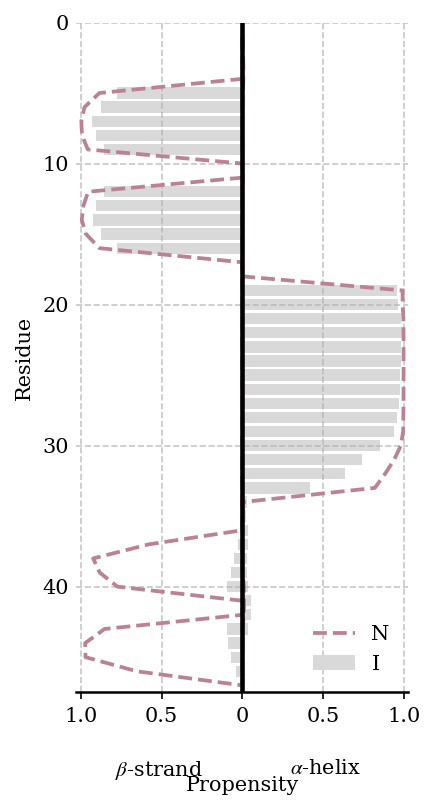

In [40]:
# secondary-structure propensity of the intermediate state relative to the native state
# beta to the left, alpha to the right
# I: 0.35 < Q < 0.7
# N: Q > 0.7


# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = data['EEHEE_rd4_0871-No-His']['wopt_array'][elidx]

# state definitions
mask_I = (Q_all > 0.35) & (Q_all < 0.7)
mask_N = Q_all > 0.7

# weighted propensities
alpha_I = np.average(helicity[mask_I], axis=0, weights=wopt[mask_I])
beta_I = np.average(strand[mask_I], axis=0, weights=wopt[mask_I])

alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3., 5.5))

# intermediate state as bars
ax.barh(residues, -beta_I, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_I, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()  # residue numbering increases from top to bottom

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(
    0.25, -0.10,
    r"$\beta$-strand",
    transform=ax.transAxes,
    ha="center",
    va="top"
)

ax.text(
    0.75, -0.10,
    r"$\alpha$-helix",
    transform=ax.transAxes,
    ha="center",
    va="top"
)

# y ticks: every 10 residues
yticks = np.arange(0, len(residues), 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('N_I_states_SS.pdf')
plt.show()

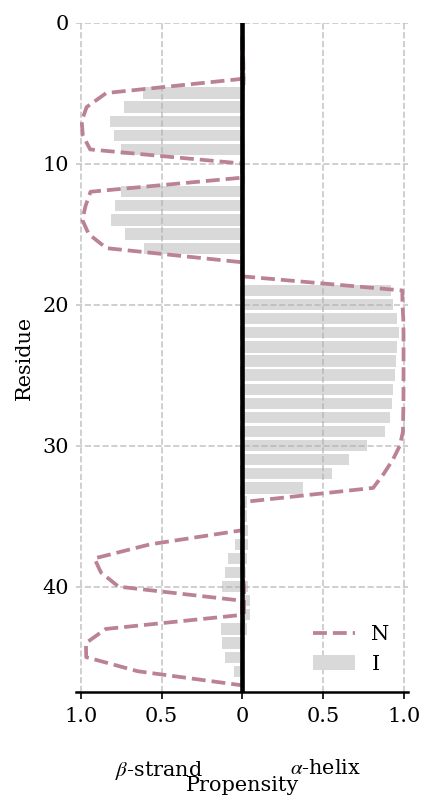

In [41]:
# secondary-structure propensity of the intermediate state relative to the native state
# beta to the left, alpha to the right
# I: 0.35 < Q < 0.7
# N: Q > 0.7


# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# prior weights - not posterior!
wopt = data['EEHEE_rd4_0871-No-His']['wopt_array'][0] 

# state definitions
mask_I = (Q_all > 0.35) & (Q_all < 0.7)
mask_N = Q_all > 0.7

# weighted propensities
alpha_I = np.average(helicity[mask_I], axis=0, weights=wopt[mask_I])
beta_I = np.average(strand[mask_I], axis=0, weights=wopt[mask_I])

alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3., 5.5))

# intermediate state as bars
ax.barh(residues, -beta_I, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_I, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()  # residue numbering increases from top to bottom

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(
    0.25, -0.10,
    r"$\beta$-strand",
    transform=ax.transAxes,
    ha="center",
    va="top"
)

ax.text(
    0.75, -0.10,
    r"$\alpha$-helix",
    transform=ax.transAxes,
    ha="center",
    va="top"
)

# y ticks: every 10 residues
yticks = np.arange(0, len(residues), 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('N_I_states_SS_prior.pdf')
plt.show()

Intermediate population:  0.06659951789393698


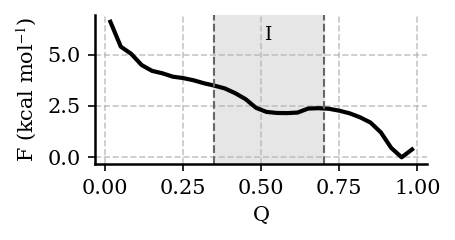

In [9]:
# control comparison with NMR reweighted ensemble

# plot 1D FEL
# free energy landscape of folding as a function of Q

ntrajs = 10
nbins = 30

k = 0.008314
T = 293.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# state boundaries
U_cutoff = 0.35
I_cutoff = 0.70

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    tmpQ = np.loadtxt(f'../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
    okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)

    if traj == trajs[0]:
        Q = tmpQ[okframes]
    else:
        Q = np.concatenate((Q, tmpQ[okframes]), axis=0)

w_post = np.load('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
intermediate = np.where((Q > U_cutoff) & (Q < I_cutoff))[0]

print('Intermediate population: ', np.sum(w_post[intermediate])/np.sum(w_post))

# calculate folding free energy: folded vs unfolded
folded = np.where(Q > U_cutoff)[0]
unfolded = np.where(Q < U_cutoff)[0]

dG_post = -kT * np.log(
    np.sum(w_post[folded]) / np.sum(w_post[unfolded])
) * kj_to_kcal

# calculate posterior FEL
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)
p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

# intermediate-state region: 0.35 < Q < 0.7
ax.axvspan(U_cutoff, I_cutoff, color="0.9", zorder=0)
ax.axvline(U_cutoff, color="0.4", ls="--", lw=1)
ax.axvline(I_cutoff, color="0.4", ls="--", lw=1)

ax.text(
    (U_cutoff + I_cutoff) / 2,
    ax.get_ylim()[1] * 0.92,
    "I",
    ha="center",
    va="top",
    fontsize=9
)

ax.set_xlabel("Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")



ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig(
    f'posterior_fel_1D_Q_NMRrew_elbow.pdf',
    bbox_inches="tight"
)
plt.show()

Intermediate population:  0.04133192968169486


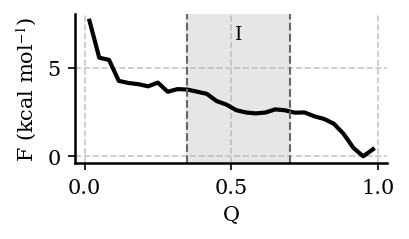

In [14]:
# control comparison with NMR reweighted ensemble posterior 2

# plot 1D FEL
# free energy landscape of folding as a function of Q

ntrajs = 10
nbins = 30

k = 0.008314
T = 293.0
kT = k * T
kj_to_kcal = 0.239005736

COLOR_POST = "black"

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# state boundaries
U_cutoff = 0.35
I_cutoff = 0.70

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    tmpQ = np.loadtxt(f'../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
    okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)

    if traj == trajs[0]:
        Q = tmpQ[okframes]
    else:
        Q = np.concatenate((Q, tmpQ[okframes]), axis=0)

w_post = np.load('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_wopt.npy') # posterior 2
intermediate = np.where((Q > U_cutoff) & (Q < I_cutoff))[0]

print('Intermediate population: ', np.sum(w_post[intermediate])/np.sum(w_post))

# calculate folding free energy: folded vs unfolded
folded = np.where(Q > U_cutoff)[0]
unfolded = np.where(Q < U_cutoff)[0]

dG_post = -kT * np.log(
    np.sum(w_post[folded]) / np.sum(w_post[unfolded])
) * kj_to_kcal

# calculate posterior FEL
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)
p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
valid = p_post > 0
fel_post[valid] = -np.log(p_post[valid]) * kT
fel_post = (fel_post - np.nanmin(fel_post)) * kj_to_kcal

# plot
fig, ax = plt.subplots(figsize=(3.0, 1.7))

ax.plot(bin_centers, fel_post, color=COLOR_POST, lw=2)

# intermediate-state region: 0.35 < Q < 0.7
ax.axvspan(U_cutoff, I_cutoff, color="0.9", zorder=0)
ax.axvline(U_cutoff, color="0.4", ls="--", lw=1)
ax.axvline(I_cutoff, color="0.4", ls="--", lw=1)

ax.text(
    (U_cutoff + I_cutoff) / 2,
    ax.get_ylim()[1] * 0.92,
    "I",
    ha="center",
    va="top",
    fontsize=9
)

ax.set_xlabel("Q")
ax.set_ylabel(r"F (kcal mol$^{-1}$)")



ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", top=False, right=False)

plt.tight_layout()
plt.savefig(
    f'posterior_fel_1D_Q_NMRrew_post2.pdf',
    bbox_inches="tight"
)
plt.show()

Posterior 1: phi = 0.8967, chi2 = 2.9571
Posterior 2: phi = 0.4153, chi2 = 0.0010


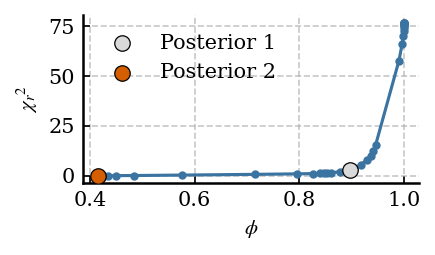

In [8]:
# chi2 vs phi from the NMR ensemble

# reweighting data NMR
wopt_array = np.load('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]
chi2 = rewdata[0,:]

# posterior 1 = elbow
wopt1 = np.load('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
# posterior 2 = final with phi > 0.1
wopt2 = np.load('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_wopt.npy')

# identify the three posterior points
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1: phi = {phi[idx_post1]:.4f}, chi2 = {chi2[idx_post1]:.4f}")
print(f"Posterior 2: phi = {phi[idx_post2]:.4f}, chi2 = {chi2[idx_post2]:.4f}")

# colours
COLOR_CURVE = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"

# sort by phi for a clean line
order = np.argsort(phi)

fig, ax = plt.subplots(figsize=(3, 1.8))

ax.plot(phi[order], chi2[order], "-o", color=COLOR_CURVE, markersize=3, linewidth=1.5, zorder=2)

# highlight selected posteriors
ax.scatter(phi[idx_post1], chi2[idx_post1], s=55, color=COLOR_POST1, edgecolor="black", linewidth=0.6, label="Posterior 1", zorder=4)
ax.scatter(phi[idx_post2], chi2[idx_post2], s=55, color=COLOR_POST2, edgecolor="black", linewidth=0.6, label="Posterior 2", zorder=4)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\chi$$_{r}$$^{2}$")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig("chi2_vs_phi_NMR.pdf") 
plt.show()

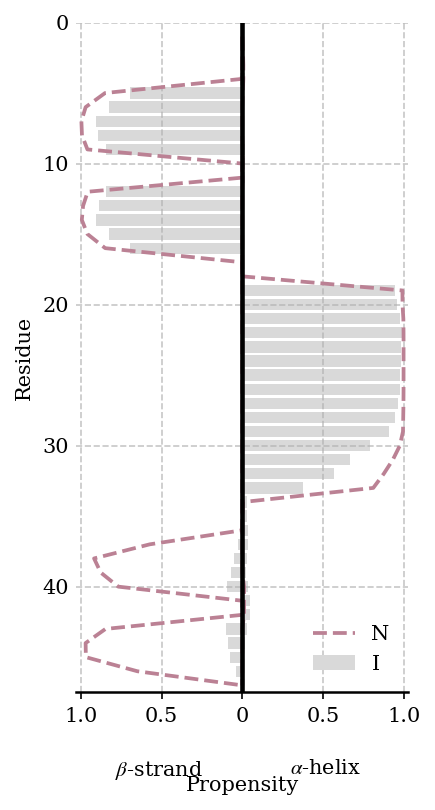

In [43]:
# NMR reweighted posterior elbow
# secondary-structure propensity of the intermediate state relative to the native state
# beta to the left, alpha to the right
# I: 0.35 < Q < 0.7
# N: Q > 0.7


# calculate per-frame secondary-structure assignments
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load('../../HDX_project/BIOEMU_DATA/EEHEE_rd4_0871-No-His/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# state definitions
mask_I = (Q > 0.35) & (Q < 0.7)
mask_N = Q > 0.7

# weighted propensities
alpha_I = np.average(helicity[mask_I], axis=0, weights=wopt[mask_I])
beta_I = np.average(strand[mask_I], axis=0, weights=wopt[mask_I])

alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3., 5.5))

# intermediate state as bars
ax.barh(residues, -beta_I, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_I, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()  # residue numbering increases from top to bottom

# y-axis label
ax.set_ylabel("Residue")

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis labels
ax.set_xlabel("Propensity", labelpad=24)

ax.text(
    0.25, -0.10,
    r"$\beta$-strand",
    transform=ax.transAxes,
    ha="center",
    va="top"
)

ax.text(
    0.75, -0.10,
    r"$\alpha$-helix",
    transform=ax.transAxes,
    ha="center",
    va="top"
)

# y ticks: every 10 residues
yticks = np.arange(0, len(residues), 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)

ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('N_I_states_SS_NMRrew_elbow.pdf')
plt.show()

Posterior 1 phi = 0.8967
Posterior 2 phi = 0.4153


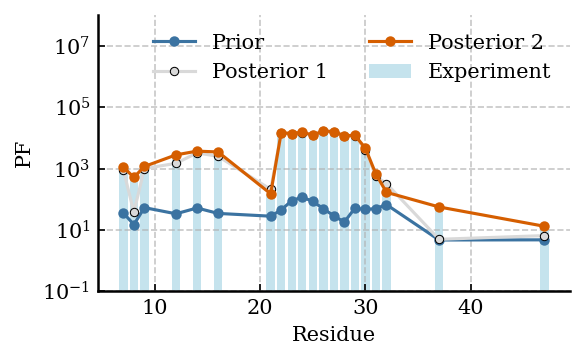

In [13]:
# comparison of NMR protection factors (Nguyen 2018 rates) and prior/posterior

protein = 'EEHEE_rd4_0871-No-His'

exp = pd.read_csv(f'../../HDX_project/EXP_DATA/PF_Nguyen_2018/{protein}.csv')

# get fopen
fopen = np.load(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/O.npy')
res = np.loadtxt(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# posterior 2 = final
wopt2 = np.load(f'../../HDX_project/BIOEMU_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi values
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1 phi = {phi[idx_post1]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF1_plot = PF1[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, ax = plt.subplots(figsize=(4,2.5))

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", alpha=0.7, label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF1_plot, "-o", color=COLOR_POST1, markeredgecolor="black", markeredgewidth=0.5, markersize=4, linewidth=1.5, label=rf"Posterior 1", zorder=4)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label=rf"Posterior 2", zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1, 1e8)
ax.legend(frameon=False, ncol=2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig('EXP_vs_CALC_PF_NMR.pdf')
plt.show()

/tmp/ipykernel_316883/721993959.py:114: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


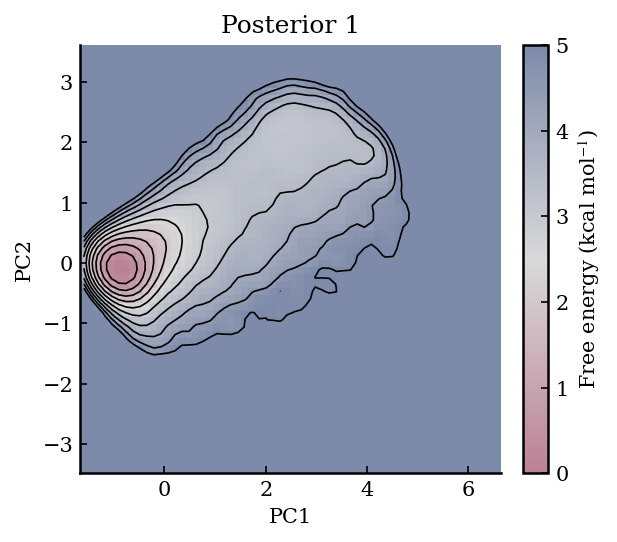

In [44]:
# PCA FEL
# FEL of posterior 1 (elbow) as a function of PC1 and PC2
# PCA coordinates contain all frames, so first sub-index using okframes
# from each trajectory in exactly the same sorted trajectory order

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 5.0
sigma = 1.0

# load PCA coordinates for all frames
pca = np.loadtxt(f'../{ensemble_master_dir}/{protein}/PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# get trajectories in exactly the same order used for PCA/reweighting
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# load trajectory frame ranges written by PCA script
frame_info = np.loadtxt(f'../{ensemble_master_dir}/{protein}/PCA/trajectory_frames.txt', dtype=str)

# build global indices corresponding to okframes from each trajectory
global_okframes = []

for i, traj in enumerate(trajs):
    traj_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert traj_name == traj, f"Trajectory order mismatch: PCA has {traj_name}, current order has {traj}"

    okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    global_okframes.append(start + okframes)

global_okframes = np.concatenate(global_okframes)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# posterior 1 weights
wopt = np.asarray(data[protein]['wopt_array'][elidx], dtype=float)

# optional: drop synthetic frames at the end if present
pc1_use = np.asarray(pc1, dtype=float)
pc2_use = np.asarray(pc2, dtype=float)

if synframes > 0:
    pc1_use = pc1_use[:-synframes]
    pc2_use = pc2_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(pc1_use) == len(pc2_use) == len(wopt), f"PC1, PC2, and wopt must have the same length: {len(pc1_use)}, {len(pc2_use)}, {len(wopt)}"

# normalize weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(pc1_use), np.max(pc1_use)
ymin, ymax = np.min(pc2_use), np.max(pc2_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(pc1_use, pc2_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 293.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plot
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(f'{protein}_PC1_PC2_FEL_posterior1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_316883/4150112062.py:114: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


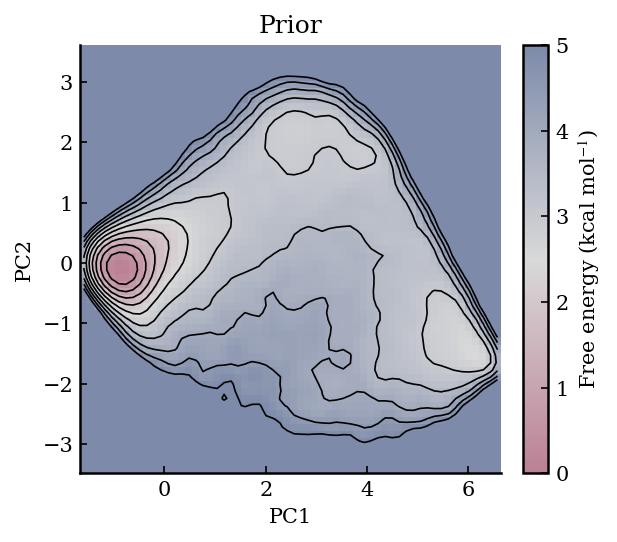

In [45]:
# PCA FEL
# FEL of posterior 1 (elbow) as a function of PC1 and PC2
# PCA coordinates contain all frames, so first sub-index using okframes
# from each trajectory in exactly the same sorted trajectory order

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 5.0
sigma = 1.0

# load PCA coordinates for all frames
pca = np.loadtxt(f'../{ensemble_master_dir}/{protein}/PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# get trajectories in exactly the same order used for PCA/reweighting
trajs = sorted(find_xtc_filenames(f'../{ensemble_master_dir}/{protein}/'))

# load trajectory frame ranges written by PCA script
frame_info = np.loadtxt(f'../{ensemble_master_dir}/{protein}/PCA/trajectory_frames.txt', dtype=str)

# build global indices corresponding to okframes from each trajectory
global_okframes = []

for i, traj in enumerate(trajs):
    traj_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert traj_name == traj, f"Trajectory order mismatch: PCA has {traj_name}, current order has {traj}"

    okframes = np.loadtxt(f'../{ensemble_master_dir}/{protein}/M13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    global_okframes.append(start + okframes)

global_okframes = np.concatenate(global_okframes)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# prior weights
wopt = np.asarray(data[protein]['wopt_array'][0], dtype=float)

# optional: drop synthetic frames at the end if present
pc1_use = np.asarray(pc1, dtype=float)
pc2_use = np.asarray(pc2, dtype=float)

if synframes > 0:
    pc1_use = pc1_use[:-synframes]
    pc2_use = pc2_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(pc1_use) == len(pc2_use) == len(wopt), f"PC1, PC2, and wopt must have the same length: {len(pc1_use)}, {len(pc2_use)}, {len(wopt)}"

# normalize weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(pc1_use), np.max(pc1_use)
ymin, ymax = np.min(pc2_use), np.max(pc2_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(pc1_use, pc2_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 293.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plot
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(f'{protein}_PC1_PC2_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

In [47]:
# ------------------------------------------------------------------
# Identify and extract representative structures from PCA FEL minima.
#
# The PCA coordinates contain all frames from all trajectories, while
# the reweighting weights only correspond to the retained "okframes".
# The code therefore reconstructs the correct global frame indices,
# subsets PC1/PC2 to the reweighted ensemble, builds a smoothed 2D
# free-energy landscape, and automatically detects the lowest local
# minima. For each minimum, representative conformations are selected
# based on both proximity in PCA space and population weight, then the
# corresponding original trajectory frames are written as PDB files.
# ------------------------------------------------------------------

import os
import mdtraj as md
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter, minimum_filter

protein = proteins[0]
base_dir = f'../{ensemble_master_dir}/{protein}/'
outdir = './pca_structures_auto/'
os.makedirs(outdir, exist_ok=True)

n_structures = 10
n_candidates = 200
n_minima = 3
nbins = 60
max_energy = 5.0
sigma = 1.0
min_filter_size = 5
min_bin_separation = 6
max_detect_energy = 4.0
synframes = 0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

def detect_local_minima(F, xc, yc, n_minima=4, min_filter_size=5, min_bin_separation=6, max_detect_energy=4.0):
    F_work = np.array(F, copy=True)
    F_work[np.isnan(F_work)] = np.inf
    local_min_mask = F_work == minimum_filter(F_work, size=min_filter_size, mode='nearest')
    candidate_mask = local_min_mask & np.isfinite(F_work) & (F_work <= max_detect_energy)
    candidate_bins = np.argwhere(candidate_mask)
    candidate_energies = np.array([F_work[i,j] for i,j in candidate_bins])
    order = np.argsort(candidate_energies)
    selected = []

    for idx in order:
        i, j = candidate_bins[idx]
        keep = True
        for si, sj, sx, sy, sE in selected:
            if np.sqrt((i - si)**2 + (j - sj)**2) < min_bin_separation:
                keep = False
                break
        if keep:
            selected.append((i, j, xc[i], yc[j], F_work[i,j]))
        if len(selected) >= n_minima:
            break

    return selected

# load PCA coordinates for all frames
pca = np.loadtxt(base_dir + 'PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# trajectory order must match PCA/reweighting
traj_names = sorted(find_xtc_filenames(base_dir))
traj_paths = [base_dir + traj_name for traj_name in traj_names]

# frame ranges written by PCA script
frame_info = np.loadtxt(base_dir + 'PCA/trajectory_frames.txt', dtype=str)
frame_info = np.atleast_2d(frame_info)

# build mapping from reweighted-frame index -> trajectory and original frame
global_okframes = []
frame_traj_path = []
frame_traj_name = []
frame_local = []

for i, (traj_name, traj_path) in enumerate(zip(traj_names, traj_paths)):
    info_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert info_name == traj_name, f"Trajectory order mismatch: {info_name} != {traj_name}"

    okframes = np.loadtxt(base_dir + f'M13DH_scaled/okframes_{traj_name[:-4]}.txt').astype(int)
    okframes = np.atleast_1d(okframes)

    global_okframes.append(start + okframes)
    frame_traj_path.extend([traj_path] * len(okframes))
    frame_traj_name.extend([traj_name] * len(okframes))
    frame_local.extend(okframes)

global_okframes = np.concatenate(global_okframes)
frame_traj_path = np.asarray(frame_traj_path)
frame_traj_name = np.asarray(frame_traj_name)
frame_local = np.asarray(frame_local, dtype=int)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# weights used for FEL
wopt = np.asarray(data[protein]['wopt_array'][0], dtype=float)

if synframes > 0:
    pc1 = pc1[:-synframes]
    pc2 = pc2[:-synframes]
    wopt = wopt[:-synframes]
    frame_traj_path = frame_traj_path[:-synframes]
    frame_traj_name = frame_traj_name[:-synframes]
    frame_local = frame_local[:-synframes]

assert len(pc1) == len(pc2) == len(wopt) == len(frame_traj_path), f"PC1, PC2, weights, and frame mapping must have the same length: {len(pc1)}, {len(pc2)}, {len(wopt)}, {len(frame_traj_path)}"

# normalize weights
wopt = wopt / np.sum(wopt)

# build FEL
xmin, xmax = np.min(pc1), np.max(pc1)
ymin, ymax = np.min(pc2), np.max(pc2)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

H_post, xedges, yedges = np.histogram2d(pc1, pc2, bins=[xbins, ybins], weights=wopt)
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)
F_post = hist_to_fel(H_post_smooth, kB=0.0019872041, T=293.0)

xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])

# auto-detect minima
minima = detect_local_minima(F_post, xc, yc, n_minima=n_minima, min_filter_size=min_filter_size, min_bin_separation=min_bin_separation, max_detect_energy=max_detect_energy)

print('\nDetected minima:')
print('id  PC1  PC2  free_energy')
for k, (i, j, pc1_min, pc2_min, E_min) in enumerate(minima, start=1):
    print(f'{k:2d}  {pc1_min:8.3f}  {pc2_min:8.3f}  {E_min:8.3f}')

with open(outdir + 'detected_minima.txt', 'w') as f:
    f.write('minimum_id pc1 pc2 free_energy_kcal_per_mol\n')
    for k, (i, j, pc1_min, pc2_min, E_min) in enumerate(minima, start=1):
        f.write(f'minimum_{k:02d} {pc1_min:.6f} {pc2_min:.6f} {E_min:.6f}\n')

# extract representative structures for each minimum
for k, (i_bin, j_bin, pc1_min, pc2_min, E_min) in enumerate(minima, start=1):
    minimum_name = f'minimum_{k:02d}'

    distance = np.sqrt((pc1 - pc1_min)**2 + (pc2 - pc2_min)**2)
    candidate_idx = np.argsort(distance)[:min(n_candidates, len(distance))]

    candidate_distance = distance[candidate_idx]
    candidate_weight = wopt[candidate_idx]

    distance_rank = np.argsort(np.argsort(candidate_distance))
    weight_rank = np.argsort(np.argsort(-candidate_weight))
    combined_rank = distance_rank + weight_rank

    selected_local = np.argsort(combined_rank)[:n_structures]
    selected = candidate_idx[selected_local]
    selected = selected[np.argsort(combined_rank[selected_local])]

    print(f'\n{minimum_name}: minimum = ({pc1_min:.3f}, {pc2_min:.3f}), F = {E_min:.3f} kcal mol^-1')
    print('rank  traj  frame  PC1  PC2  distance  weight')

    with open(outdir + f'{minimum_name}_summary.txt', 'w') as f:
        f.write(f'# {minimum_name}: minimum = ({pc1_min:.6f}, {pc2_min:.6f}), F = {E_min:.6f} kcal mol^-1\n')
        f.write('rank traj frame pc1 pc2 distance weight\n')

        for rank, idx in enumerate(selected, start=1):
            traj_path = frame_traj_path[idx]
            traj_name = frame_traj_name[idx]
            frame = frame_local[idx]

            print(f'{rank:2d}  {traj_name}  {frame:6d}  {pc1[idx]:8.3f}  {pc2[idx]:8.3f}  {distance[idx]:8.4f}  {wopt[idx]:.6e}')
            f.write(f'{rank} {traj_name} {frame} {pc1[idx]:.6f} {pc2[idx]:.6f} {distance[idx]:.6f} {wopt[idx]:.8e}\n')

            structure = md.load_frame(traj_path, frame, top=base_dir + 'protein.pdb')
            structure.save_pdb(outdir + f'{minimum_name}_rep{rank:02d}_{traj_name[:-4]}_frame{frame}.pdb')


Detected minima:
id  PC1  PC2  free_energy
 1    -0.899    -0.113     0.000
 2     6.163    -1.534     2.523
 3     2.701     2.137     2.821

minimum_01: minimum = (-0.899, -0.113), F = 0.000 kcal mol^-1
rank  traj  frame  PC1  PC2  distance  weight
 1  traj0.xtc     643    -0.900    -0.114    0.0005  1.044266e-05
 2  traj3.xtc    4696    -0.900    -0.113    0.0010  1.044266e-05
 3  traj6.xtc    1909    -0.903    -0.117    0.0050  1.044266e-05
 4  traj9.xtc    7356    -0.891    -0.106    0.0106  1.044266e-05
 5  traj0.xtc     458    -0.902    -0.122    0.0095  1.044266e-05
 6  traj9.xtc    5579    -0.898    -0.113    0.0010  1.044266e-05
 7  traj7.xtc    8068    -0.895    -0.114    0.0051  1.044266e-05
 8  traj0.xtc    6004    -0.909    -0.109    0.0106  1.044266e-05
 9  traj7.xtc    2532    -0.908    -0.109    0.0096  1.044266e-05
10  traj6.xtc    4331    -0.904    -0.111    0.0053  1.044266e-05

minimum_02: minimum = (6.163, -1.534), F = 2.523 kcal mol^-1
rank  traj  frame  PC1  PC

In [ ]:
# the structures of these representative frames correspond to the same native and intermediate state (minima 0 and 2) as characterised above with Q and RMSD (minimum 1 is the unfolded state)